# Historia de clientes: cierre del experimento grupal

**Documentación actualizada al 7 de noviembre de 2026.** Integrantes: Tomás Henseler, Clara M. Rodríguez y Ezequiel Abregú. Tutor: Alejandro Bolaños.

Recorrido: antecedentes del grupo hasta **6cf189c (01-14)**, cuatro familias completas con diez semillas y ampliaciones auditadas de cambios relativos/rankings con veinte semillas totales por brazo.

Este notebook conserva salidas reales ejecutadas sobre **tablas agregadas**. No necesita dataset, predicciones individuales, credenciales ni VM. No entrena modelos ni abre meses adicionales. Las semillas comparten clientes y agosto: describen variación del algoritmo, no meses independientes.

En el repositorio, ejecutar desde la raíz o desde `notebooks/`. En Colab, abrir este archivo y subir `tutoria_historia_documentacion_20261107.zip` cuando lo pida. Las figuras de antecedentes están incorporadas al notebook. El ZIP solo contiene documentación y agregados.


## El problema y el baseline

El objetivo del ejercicio es identificar clientes por abandonar el banco. En la métrica económica usada por el grupo, contactar a un BAJA+2 suma 1.072.500 y contactar a otro cliente resta 27.500. Un acierto compensa 39 errores; el punto de equilibrio del estímulo corresponde a una probabilidad de BAJA+2 de 2,5 %. Estos valores son los del ejercicio, no una estimación de beneficio real del banco.

El baseline de la cátedra ya contiene historia: 152 variables actuales, lag1 y lag2, y delta1 y delta2, total 760 columnas. Lag busca el mes calendario exacto del mismo cliente; delta es actual menos lag. No se incluyen ID, foto_mes ni clase como predictores en los notebooks revisados.

| Control | Entrenamiento | Ajuste y función |
|---|---|---|
| A | Mayo–junio | Control del experimento principal; ventana adaptada para tener hasta cuatro meses anteriores |
| A-consigna / AC | Marzo–junio | Conserva meses de la consigna, con parámetros elegidos sobre A; AC añade correcciones de dos roturas Master en octubre |
| ACO | Marzo–junio | Ajuste propio del 07, 339 árboles; control de nuestra serie de AUC |
| ACH | Marzo–junio o banco por clientes, según el experimento | AC más 120 features de historia curada sobre 30 variables; no es el baseline de la cátedra |

La evaluación original usa agosto para AUC, early stopping y N; octubre para el contraste principal y septiembre como control adicional. Entrenamiento positivo: BAJA+1 o BAJA+2; AUC de evaluación positiva: BAJA+2. La ganancia se calcula exclusivamente con BAJA+2. Los distintos ajustes, ventanas y métricas no se mezclan en un único ranking de ganadores.

Diferencias documentadas frente a la referencia de la cátedra: saneamiento retrospectivo de roturas; septiembre como mes adicional; y, para A, ventana mayo–junio. La búsqueda propia de marzo–junio del 07 elevó la AUC de selección, pero no la ganancia posterior. Consultar al tutor qué adaptaciones acepta.

Hipótesis original: al menos una variante con tres o cuatro meses mejora la ganancia de A en octubre bajo una regla propia predefinida. Hipótesis secundaria: la ganancia crece al agregar meses. La principal no se confirmó bajo esa regla; la secundaria tuvo una señal descriptiva más clara de dos a tres meses que de tres a cuatro.

La regla no fue exigida por la consigna: pide p de Wilcoxon ajustado por Holm menor que 0,05 en seis contrastes, diferencia media positiva en octubre y no negativa en septiembre. Todas las variantes cumplieron las condiciones de dirección, pero ninguna la de p ajustado. No pasar no demuestra efecto nulo.



## Qué se probó y qué dio

| Paso | Pregunta | Resultado disponible |
|---|---|---|
| Preparación y mínimo 01–02 | ¿Datos, clase y pipeline están listos? | Controles de filas/clases; ensayo A–LT4 con cinco semillas en agosto |
| 1 Prueba principal 03–04 | ¿Tres o cuatro meses mejoran sobre dos? | Ventajas medias de ganancia, ninguna pasa la regla de seis contrastes |
| 2 Exploraciones 05–11 | ¿Otras representaciones o puntajes suman? | Señales pequeñas y dependientes del mes; resultados posteriores a abrir test |
| 3 Cambio de pregunta 12 | ¿Cuánto vale la historia y entrenar más cerca? | Unos 20 M/mes de banda al recuperar historia básica; mejoras variables al acercar la ventana |
| 4 Banco por clientes 13 | ¿Podemos medir con menor ruido? | Cuatro bloques solos: +0,74 a +1,60 M/mes frente a ACH en el banco |
| 5 Combinación 14 | ¿Los cuatro bloques juntos se complementan? | +1,9263 M/mes; señal intermedia; no supera claramente la mejor idea sola |
| Aporte complementario | ¿Cambiar la representación de la historia mejora ACO en agosto? | Cambios relativos y rankings, explicados y comparados directamente con veinte pares por estrategia |

### Preparación y prueba mínima

El original tiene 4.707.495 filas y 154 columnas; el corte 2019 tiene 1.563.565 filas y cero claves duplicadas. La clase se construye con calendario hasta diciembre de 2019. Se identificaron 23 casos de variable/mes roto y luego dos correcciones Master adicionales. La detección de calidad usa información retrospectiva y se declara como limitación. El ensayo mínimo 02 compara A con LT4 en agosto y sirve para probar el pipeline; no es un test independiente.

### Paso 1 La regla y los dos controles

| Variante contra A | Δ septiembre M | Δ octubre M | p sin ajustar | p Holm | Pasa regla |
|---|---:|---:|---:|---:|---|
| L3 | +4.6750 | +3.4650 | 0.1211 | 0.2422 | No |
| L4 | +6.0225 | +5.0325 | 0.0293 | 0.1465 | No |
| T3 | +5.0600 | +3.6300 | 0.0410 | 0.1484 | No |
| T4 | +4.1525 | +3.6025 | 0.1562 | 0.2422 | No |
| LT3 | +6.1875 | +5.4175 | 0.0117 | 0.0703 | No |
| LT4 | +5.1150 | +5.2250 | 0.0371 | 0.1484 | No |

L suma lags/deltas, T suma pendiente, promedio, mínimo y máximo, y LT combina ambas. Las ventanas extendidas se adaptan al tipo de variable. Las diez configuraciones se evaluaron con diez semillas cada una. LT3 es la más cercana, pero p Holm 0,0703 no cumple el umbral. Agregar semillas hasta que el p baje no es una regla válida de parada.

### Paso 2 Exploraciones de 05 a 11

| Notebook | Qué agrega | Lectura |
|---|---|---|
| 05 | Ensambles y segundas diferencias | Ensambles con señales puntuales; segundas diferencias sin mejora consistente |
| 06 | Ratio3, rachas de ceros y combinación | Ratio3 dejó señal de ganancia; rachas solas generalmente desfavorables |
| 07 | Parámetros propios para marzo–junio | Mejor AUC de selección sin mejora de ganancia posterior |
| 08 | Historia curada, lags/tendencias sin quitar meses y mezclas | Señales más favorables en octubre que en septiembre |
| 09 | Eventos, ratios entre tarjetas, puntaje y hojas RF | Ahora sí hay resultados publicados en 6cf189c; el informe anterior con fuente 3b44f21 quedó desactualizado |
| 10 | Puntaje actual separado del pasado y otras particiones por cliente | Permite distinguir aporte del nivel actual y de la trayectoria de riesgo |
| 11 | Puntaje pasado con particiones B y C | Explora sensibilidad a cómo se divide a los clientes |

La historia curada (ACH) usa ratio3 (actual frente a promedio de tres fotos), z4 (apartamiento frente al pasado), relmax4 (actual frente a máximo previo) y mes_ratio3 (posición del ratio dentro del mes). El puntaje pasado usa predicciones de un modelo construido para no entrenar con el cliente que recibe el puntaje.

Para no seleccionar solo ejemplos favorables, se conservan todos los contrastes por semilla de 09–11. Diferencias de ganancia contra el control indicado; banda: promedio entre 3.000 y 6.000 envíos.

#### Contrastes del 09

| Variante | Control | Δ ganancia septiembre M | Δ ganancia octubre M | Δ banda octubre M |
|---|---|---:|---:|---:|
| ACH | AC | +1.5675 | +5.1975 | +5.4438 |
| ACE | AC | -0.4400 | +5.6100 | +5.3351 |
| ACR | AC | -1.5950 | +5.1150 | +5.9371 |
| ACP | AC | +4.7850 | +4.1250 | +5.9410 |
| ACF | AC | +1.5400 | +5.8300 | +5.3191 |
| ACK | AC | +0.7425 | +5.2525 | +4.0581 |
| ACX | AC | +1.0725 | +6.1325 | +7.2899 |
| ACE | ACH | -2.0075 | +0.4125 | -0.1087 |
| ACR | ACH | -3.1625 | -0.0825 | +0.4934 |
| ACP | ACH | +3.2175 | -1.0725 | +0.4972 |
| ACF | ACH | -0.0275 | +0.6325 | -0.1247 |
| ACK | ACH | -0.8250 | +0.0550 | -1.3857 |
| ACX | ACH | -0.4950 | +0.9350 | +1.8461 |

#### Contrastes del 10

| Variante | Control | Δ ganancia septiembre M | Δ ganancia octubre M | Δ banda octubre M |
|---|---|---:|---:|---:|
| ACH | AC | +1.5675 | +5.1975 | +5.4438 |
| ACP | AC | +4.7850 | +4.1250 | +5.9410 |
| ACP0 | AC | +5.3625 | +3.0525 | +4.3214 |
| ACPH | AC | +4.7300 | +6.7100 | +5.3088 |
| ACP_B | AC | +5.3350 | +4.6750 | +4.4189 |
| ACP_C | AC | +5.8300 | +5.7200 | +4.5517 |
| ACP | ACH | +3.2175 | -1.0725 | +0.4972 |
| ACP0 | ACH | +3.7950 | -2.1450 | -1.1224 |
| ACPH | ACH | +3.1625 | +1.5125 | -0.1349 |
| ACP_B | ACH | +3.7675 | -0.5225 | -1.0249 |
| ACP_C | ACH | +4.2625 | +0.5225 | -0.8921 |
| ACPH | ACP0 | -0.6325 | +3.6575 | +0.9874 |

#### Contrastes del 11

| Variante | Control | Δ ganancia septiembre M | Δ ganancia octubre M | Δ banda octubre M |
|---|---|---:|---:|---:|
| ACH | AC | +1.5675 | +5.1975 | +5.4438 |
| ACPH | AC | +4.7300 | +6.7100 | +5.3088 |
| ACPH_B | AC | +4.6200 | +7.5900 | +6.4594 |
| ACPH_C | AC | +5.9125 | +6.2425 | +5.9345 |
| ACPH | ACH | +3.1625 | +1.5125 | -0.1349 |
| ACPH_B | ACH | +3.0525 | +2.3925 | +1.0157 |
| ACPH_C | ACH | +4.3450 | +1.0450 | +0.4908 |

### Paso 3 Cuánto vale la historia en el 12

AC contra ACS (ACS usa solo 152 variables actuales) mejora la banda media por semilla en +20,1406 M en septiembre y +19,9258 M en octubre. La ganancia en N cambia +18,59 y +19,36 M. Es una comparación económica distinta de nuestra ablación de AUC, que dio +0,006477 AUC media en agosto con diez semillas y parámetros del 07.

El 12 también acerca los meses de entrenamiento para AC, ACH y variantes de puntaje pasado. Los efectos varían por modelo, partición y mes. Estas son las comparaciones completas por semilla:

| Variante | Control | Δ ganancia septiembre M | Δ ganancia octubre M | Δ banda octubre M |
|---|---|---:|---:|---:|
| AC | ACS | +18.5900 | +19.3600 | +19.9258 |
| ACH | AC | +1.5675 | +5.1975 | +5.4438 |
| ACPH | AC | +4.7300 | +6.7100 | +5.3088 |
| ACPH_B | AC | +4.6200 | +7.5900 | +6.4594 |
| ACPH_C | AC | +5.9125 | +6.2425 | +5.9345 |
| AC_R | AC | +1.5400 | +9.2400 | +6.4355 |
| ACH_R | AC | +6.7375 | +9.3775 | +7.5309 |
| ACPH_R | AC | +7.4800 | +8.3600 | +6.8347 |
| ACPH_R_B | AC | +6.8200 | +7.8100 | +7.5501 |
| ACPH_R_C | AC | +8.8825 | +8.8825 | +7.8672 |
| ACH_R | AC_R | +5.1975 | +0.1375 | +1.0954 |
| ACPH_R | AC_R | +5.9400 | -0.8800 | +0.3991 |
| ACPH_R_B | AC_R | +5.2800 | -1.4300 | +1.1146 |
| ACPH_R_C | AC_R | +7.3425 | -0.3575 | +1.4316 |
| ACH_R | ACH | +5.1700 | +4.1800 | +2.0871 |
| ACPH_R | ACPH | +2.7500 | +1.6500 | +1.5258 |
| ACPH_R_B | ACPH_B | +2.2000 | +0.2200 | +1.0907 |
| ACPH_R_C | ACPH_C | +2.9700 | +2.6400 | +1.9326 |

### Paso 4 Banco de pruebas del 13

Banco exploratorio: marzo–agosto, cinco grupos de clientes, dos semillas. El modelo predice clientes no vistos, pero entrena con los mismos meses de calendario que evalúa. No es validación fuera de tiempo. No carga septiembre ni octubre. Se usa la ganancia promedio de la banda, frente a ACH. Los intervalos de esta tabla son los reportados por el 13 y no incorporan la misma estimación de ruido de semillas que la tabla del 14.

| Variante | Idea | Δ M por mes frente a ACH | IC reportado |
|---|---|---:|---|
| ACH_V | Inestabilidad: variación de niveles y cambios | +1.6009 | -0.2354 a 3.4063 |
| ACH_Q | Quiebre reciente, peor cambio y cantidad de caídas | +0.7395 | -1.2638 a 2.5184 |
| ACH_T | Media/máximo de todo el pasado y tiempo desde el máximo | +1.2028 | -0.7427 a 3.0956 |
| ACH_Z | Ranking mensual de cambios con cero fijo | +1.1765 | -0.4686 a 2.8629 |

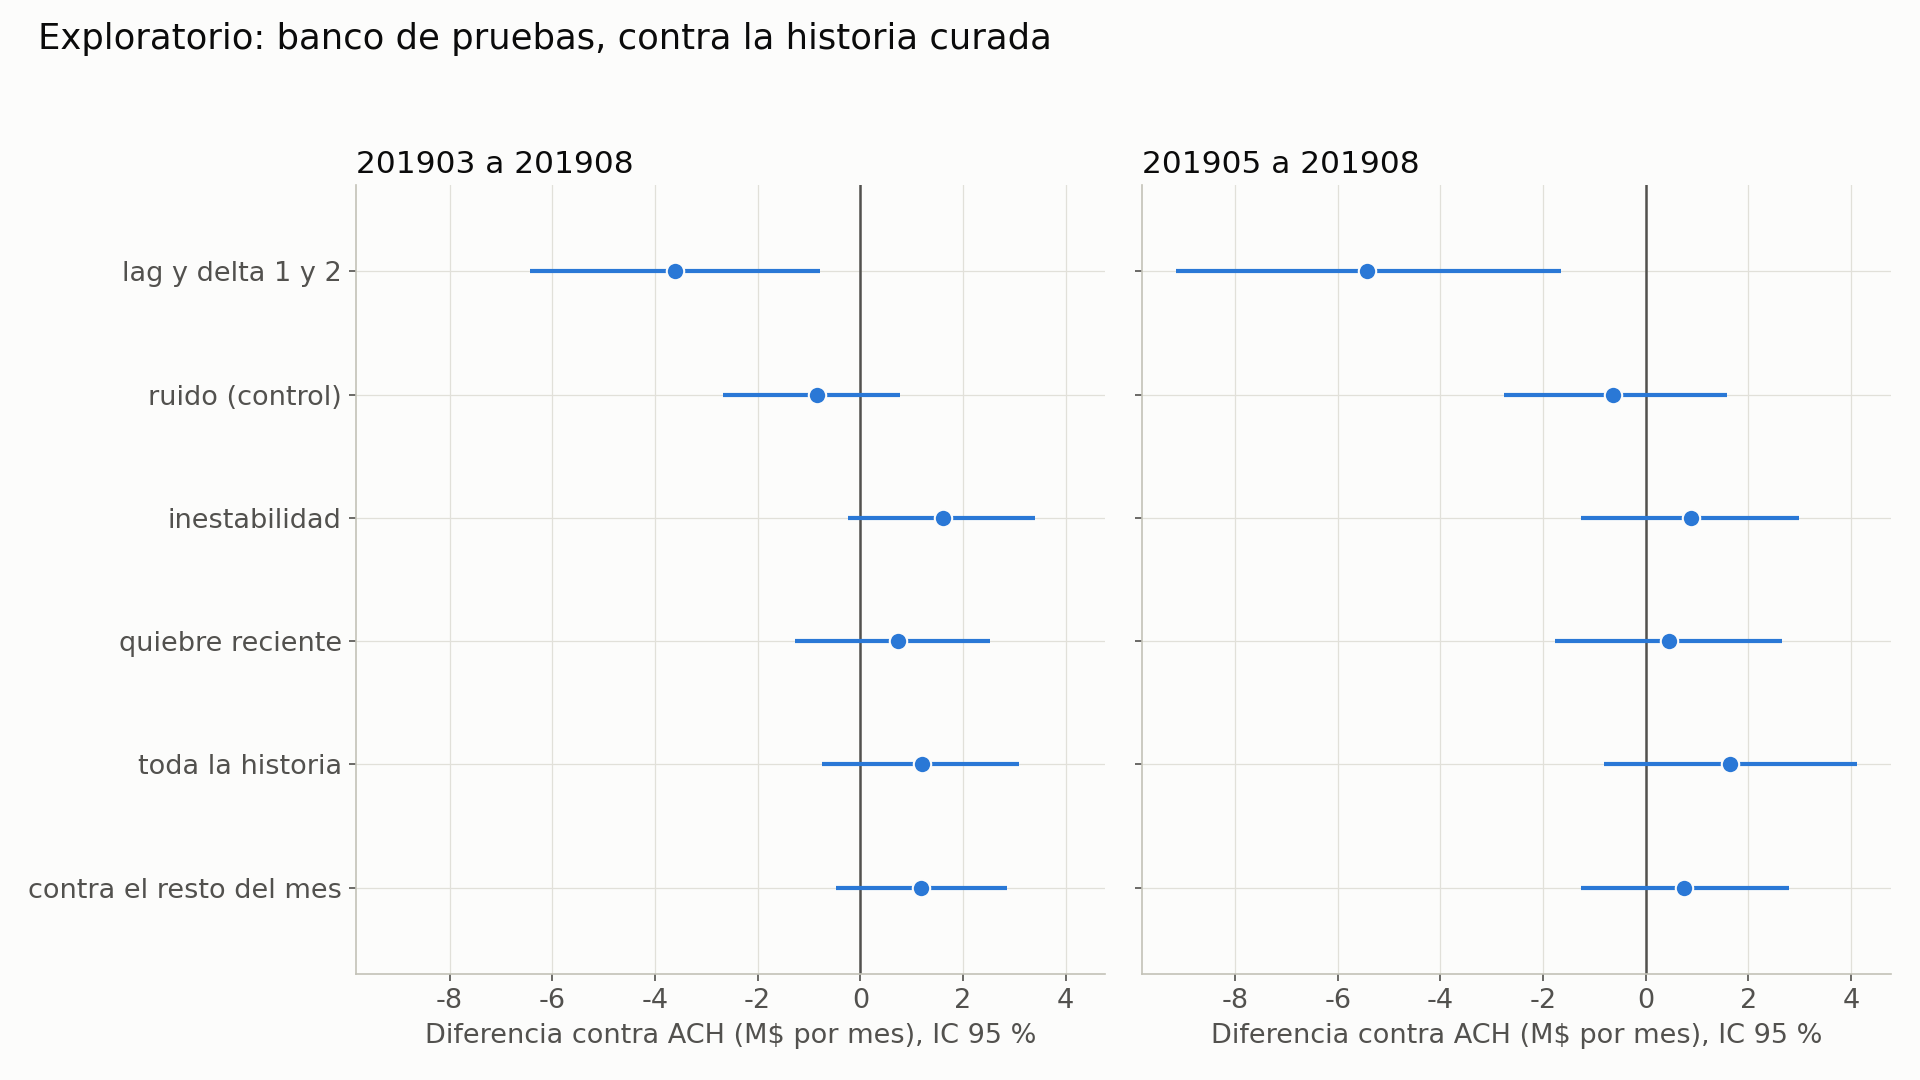

Esto también limita la novedad de nuestras pruebas: persistencia y rankings tienen parentesco con quiebre y ranking de cambios, aunque difieren en fórmulas, variables, control (ACO frente a ACH), métrica (AUC frente a ganancia) y esquema de evaluación. No afirmamos originalidad de esas familias sin aclarar ese solapamiento.

### Paso 5 Las cuatro ideas juntas en el 14

ACH_4 añade 300 columnas a ACH. Se comparan con cinco semillas sobre el banco por clientes; las candidatas individuales heredadas tienen dos semillas. El error total reportado combina estimaciones de variación de clientes y de semillas; no se interpreta como incertidumbre temporal.

| Variante frente a ACH | Semillas | Δ M por mes | IC reportado total |
|---|---:|---:|---|
| ACH_4 | 5 | +1.9263 | 0.0876 a 3.7651 |
| ACH_V | 2 | +2.0047 | 0.1717 a 3.8377 |
| ACH_Q | 2 | +1.1434 | -0.7270 a 3.0137 |
| ACH_T | 2 | +1.6066 | -0.4031 a 3.6163 |
| ACH_Z | 2 | +1.5803 | -0.1493 a 3.3098 |
| ACK | 2 | -0.4475 | -2.2270 a 1.3320 |

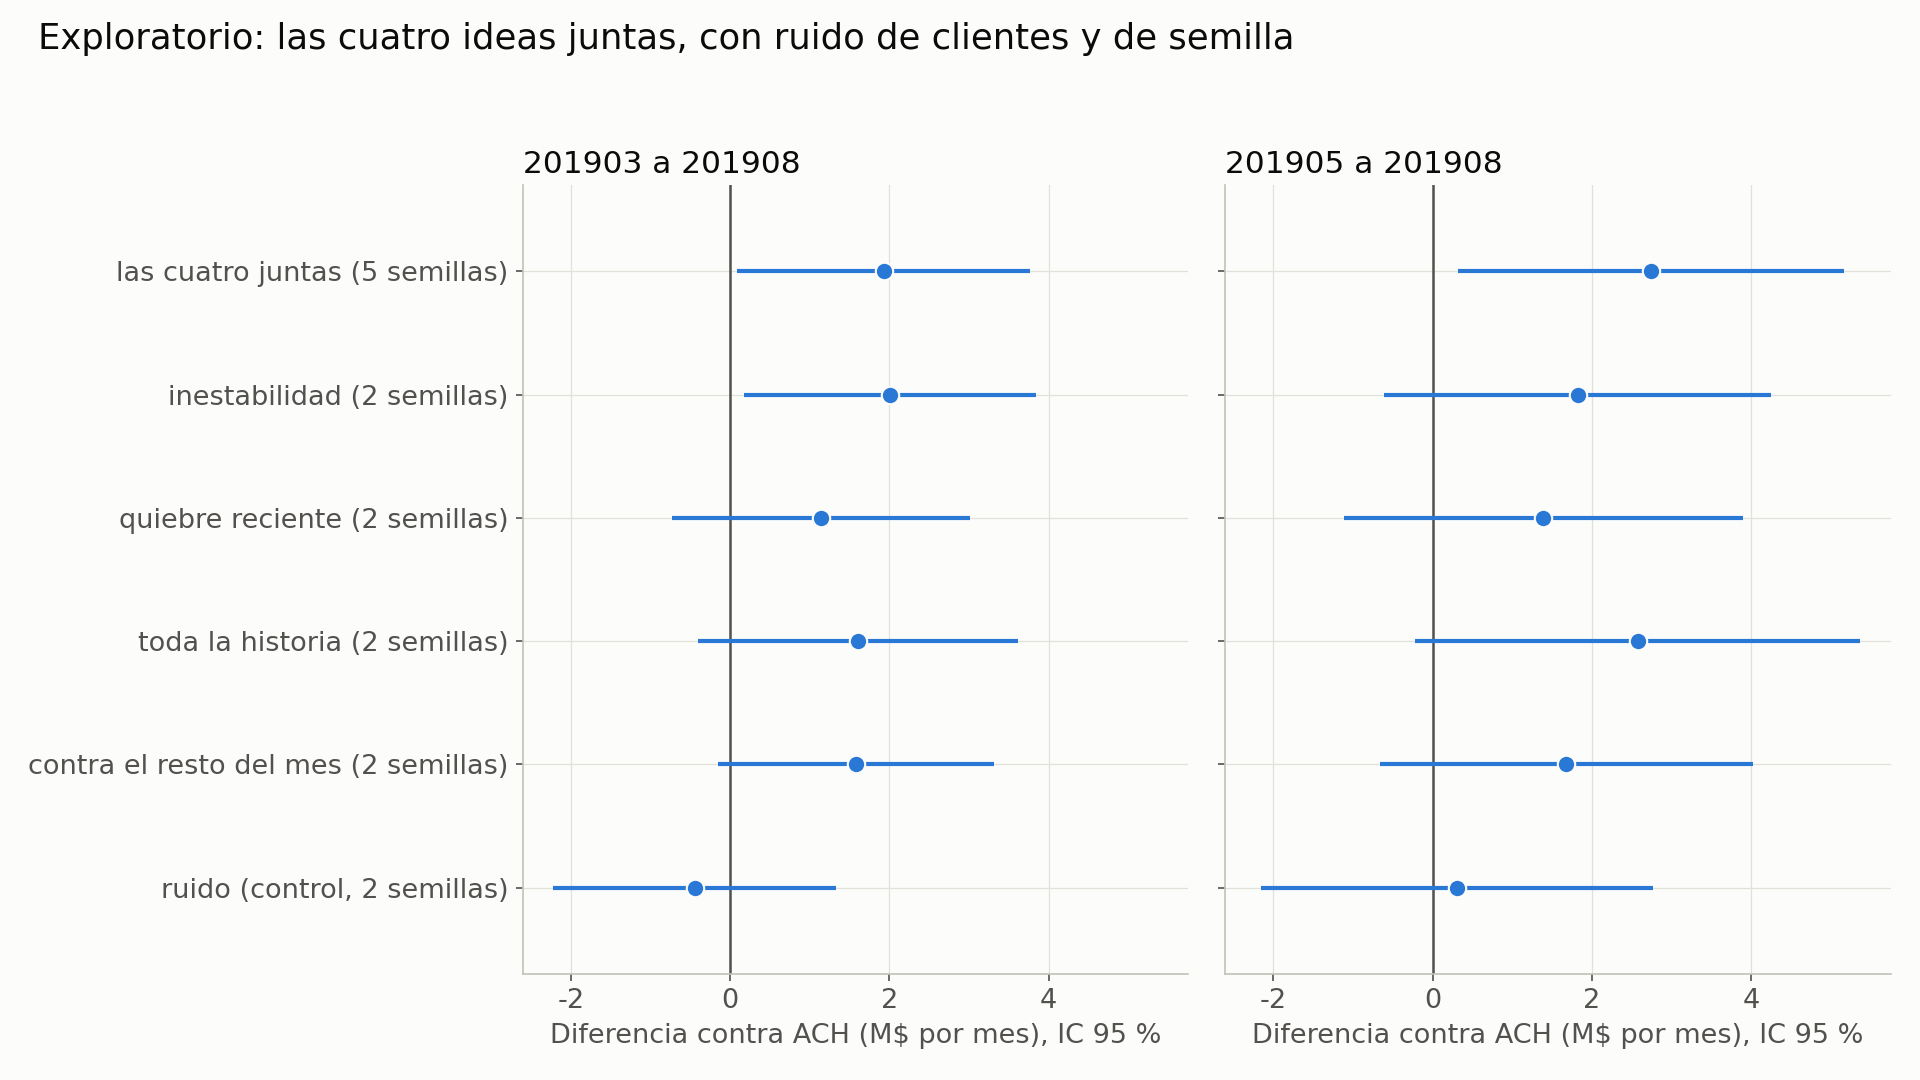

La combinación cumple la categoría de señal intermedia fijada para ese análisis: de +1,5 a menos de +3 M. Su +1,9263 M no supera numéricamente a inestabilidad sola (+2,0047 M), cuya comparación tiene menos semillas y no permite concluir equivalencia. En mayo–agosto la combinación da +2,7488 M; el ensamble reporta +1,9828 M. Queda pendiente la evaluación que propone el PDF en septiembre/octubre; esos meses ya fueron consultados, así que tampoco sería una confirmación independiente.



## Dos estrategias de historia evaluadas con veinte semillas

Comparamos dos formas de representar la historia de un cliente: su cambio relativo respecto de sí mismo y su posición respecto de los demás clientes del mes. Cada estrategia se añade por separado al baseline ACO de 760 columnas; no se reemplazan las variables originales, sus lags ni sus deltas.

### Cambios relativos: medir la variación respecto del propio pasado

La pregunta es si una caída representa un cambio importante para ese cliente, aunque su nivel de actividad sea muy distinto del de otros. La diferencia absoluta ya está en el baseline; esta estrategia agrega una diferencia normalizada por el tamaño de los valores comparados.

Para cada una de 129 variables numéricas seleccionadas se compara el valor actual con el de uno y dos meses atrás. Las dos features son:

`r1 = (actual - lag1) / (abs(actual) + abs(lag1))`

`r2 = (actual - lag2) / (abs(actual) + abs(lag2))`

El resultado está entre -1 y 1. Dos ceros observados producen cero; si falta cualquiera de los valores, se conserva NaN. No se divide solamente por el valor previo, por lo que un previo igual a cero no genera infinito. Es un cambio simétrico acotado, no un porcentaje convencional.

Ejemplo: pasar de 200 a 100 y pasar de 200.000 a 100.000 producen ambos -0,3333. La escala absoluta difiere, pero la señal de reducción relativa es la misma. Los niveles originales siguen disponibles para que el modelo distinga el tamaño de cada cliente.

Se agregan 129 × 2 = 258 columnas; total 1.018. Los lags buscan el mes calendario exacto del mismo cliente. La selección excluye indicadores, estados, fechas, edad y antigüedad; no aplica la fórmula indiscriminadamente a todos los campos.

### Rankings con cero fijo: medir la posición dentro del mes

La pregunta es si cambia la posición del cliente frente a los demás, aun cuando todos los montos se muevan de escala. Para cada una de 73 variables monetarias se calcula un percentil en cada foto mensual, por separado para los valores positivos y los negativos. No se usan etiquetas para construirlo.

Los positivos reciben percentiles entre 0 y 1. Los negativos se ordenan por magnitud absoluta dentro del grupo negativo y recuperan el signo menos. Los ceros quedan exactamente en cero y los faltantes siguen como NaN. Los empates reciben el rango promedio.

Ejemplo: si cuatro montos positivos son 100, 200, 300 y 400, sus ranks son 0,25; 0,50; 0,75 y 1. Si todos se duplican y se conserva el mismo orden y población, los ranks no cambian. Así se representa posición relativa; esto no constituye por sí solo un ajuste de inflación ni una prueba de robustez macroeconómica.

Para cada variable se agregan el rank actual, sus lags de uno y dos meses y las diferencias rank actual menos cada lag: cinco features por variable. Son 73 × 5 = 365 columnas; total 1.125. Los lags son por calendario exacto dentro del cliente. La foto completa define la distribución de referencia: cambios en su composición también pueden mover el rank de un cliente.



## Cargar y validar los agregados finales

Fuentes: `resultados/familias_final_20261106` (cuatro familias, diez pares), `resultados/ampliaciones_20261107` (dos familias, veinte pares) y `resultados/antecedentes_6cf189c` (antecedentes publicados hasta 14). Las copias parciales y los baselines provisionales no se utilizan.

Control ACO: marzo-junio, validación agosto, 339 árboles y ocho hilos en las corridas. Entrenamiento positivo BAJA+1/BAJA+2; AUC y ganancia positivas solo BAJA+2. Banda inclusiva N=3.000-6.000 y corte común N=4.000.


In [1]:
from pathlib import Path
import os, json, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

candidates = [Path(os.environ.get('HISTORIA_DOC_ROOT', '.')), Path.cwd().parent]
ROOT = next((p.resolve() for p in candidates if (p / 'resultados/ampliaciones_20261107/snapshot.json').exists()), None)
if ROOT is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Abrir desde el repositorio o descomprimir el ZIP agregado de documentación.')
    uploaded = files.upload()
    archives = [name for name in uploaded if name.endswith('.zip')]
    if len(archives) != 1:
        raise ValueError('Subir exactamente un ZIP de documentación final.')
    ROOT = Path('tutoria_documentacion').resolve()
    ROOT.mkdir(exist_ok=True)
    with zipfile.ZipFile(archives[0]) as archive:
        for member in archive.infolist():
            if not (ROOT / member.filename).resolve().is_relative_to(ROOT):
                raise ValueError('Ruta inválida en el ZIP')
        archive.extractall(ROOT)
TEN = ROOT / 'resultados/familias_final_20261106'
TWENTY = ROOT / 'resultados/ampliaciones_20261107'
OUTPUT = ROOT / 'output/tutoria'
OUTPUT.mkdir(parents=True, exist_ok=True)
FAMILIES = ['historia_reciente', 'cambios_relativos', 'persistencia', 'rankings_cero_fijo']
LABELS = dict(zip(FAMILIES, ['Historia reciente', 'Cambios relativos', 'Persistencia', 'Rankings con cero fijo']))
EXPANDED = ['cambios_relativos', 'rankings_cero_fijo']
sources = json.loads((TWENTY / 'snapshot.json').read_text())
for name, expected in sources['sha256'].items():
    assert hashlib.sha256((TWENTY / name).read_bytes()).hexdigest() == expected, name

configs, metrics, profits = {}, {}, {}
for size, folder, families in [(10, TEN, FAMILIES), (20, TWENTY, EXPANDED)]:
    for family in families:
        key = (size, family)
        config = json.loads((folder / family / 'config.json').read_text())
        seeds = config['seeds_used']
        assert len(seeds) == len(set(seeds)) == size
        assert config['train'] == [201903, 201904, 201905, 201906] and config['validation'] == 201908
        table = pd.read_csv(folder / family / 'metrics.csv')
        assert not table.duplicated(['variant', 'seed']).any()
        pivot = table.pivot(index='seed', columns='variant', values='auc')
        assert set(pivot.index) == set(seeds) and set(pivot.columns) == {'baseline', family}
        assert not pivot.isna().any().any() and ((pivot >= 0) & (pivot <= 1)).all().all()
        money = pd.read_csv(folder / family / 'profit_metrics.csv')
        assert len(money[money.kind == 'seed']) == 2 * size and len(money[money.kind == 'ensemble']) == 2
        assert not money[money.kind == 'seed'].duplicated(['variant', 'seed']).any()
        mp = money[money.kind == 'seed'].pivot(index='seed', columns='variant', values='auc')
        np.testing.assert_allclose(mp.loc[pivot.index, pivot.columns], pivot, atol=1e-10, rtol=0)
        if size == 10:
            assert json.loads((folder / family / 'status.json').read_text())['status'] == 'complete'
        configs[key], metrics[key], profits[key] = config, pivot, money
for size, families in [(10, FAMILIES), (20, EXPANDED)]:
    reference = metrics[size, families[0]].baseline
    for family in families:
        np.testing.assert_allclose(metrics[size, family].baseline.sort_index(), reference.sort_index(), atol=1e-10, rtol=0)
for family in EXPANDED:
    assert configs[20, family]['seeds_used'][:10] == configs[10, family]['seeds_used']
    old = metrics[10, family]
    np.testing.assert_allclose(metrics[20, family].loc[old.index, old.columns], old, atol=1e-10, rtol=0)
for metric in ['auc', 'gain_band_3000_6000_M', 'gain_4000_M']:
    controls = [profits[20, family].query("variant == 'baseline' and kind == 'seed'").set_index('seed')[metric].sort_index() for family in EXPANDED]
    np.testing.assert_array_equal(controls[0], controls[1])
print('Integridad OK: cuatro familias de diez pares; dos ampliaciones de veinte; baseline compartido y diez originales reproducidas.')
print('Solo documentación: no se cargaron datos de clientes ni se entrenaron modelos.')

Integridad OK: cuatro familias de diez pares; dos ampliaciones de veinte; baseline compartido y diez originales reproducidas.
Solo documentación: no se cargaron datos de clientes ni se entrenaron modelos.


## Cuatro familias completas: diez semillas

AUC media por semilla y ensamble se informan por separado. Las diferencias se calculan frente al baseline ACO de los mismos pares.

In [2]:
rows = []
for family in FAMILIES:
    pivot = metrics[10, family]
    delta = pivot[family] - pivot.baseline
    summary = json.loads((TEN / family / 'summary.json').read_text())['ensemble_auc']
    rows.append({'familia': LABELS[family], 'pares': len(delta), 'AUC baseline': pivot.baseline.mean(),
                 'AUC variante': pivot[family].mean(), 'delta AUC media': delta.mean(),
                 'favorables AUC': int((delta > 0).sum()), 'delta AUC ensamble': summary[family] - summary['baseline']})
auc10 = pd.DataFrame(rows)
display(auc10.round(6))
auc10.to_csv(OUTPUT / 'auc_10semillas.csv', index=False)

,familia,pares,AUC baseline,AUC variante,delta AUC media,favorables AUC,delta AUC ensamble
0,Historia reciente,10,0.911657,0.910525,-0.001132,3,-0.001174
1,Cambios relativos,10,0.911657,0.910749,-0.000908,4,-0.001026
2,Persistencia,10,0.911657,0.911887,0.000231,5,0.000161
3,Rankings con cero fijo,10,0.911657,0.911046,-0.000611,3,-0.000747


### Ganancia secundaria de agosto

+1.072.500 por BAJA+2 contactado y -27.500 por el resto. La banda y N=4.000 son comunes a todas las familias; no se optimiza N. Esta evaluación económica se decidió después de mirar parte de las AUC.

In [3]:
rows = []
for family in FAMILIES:
    summary = json.loads((TEN / family / 'profit_summary.json').read_text())
    band, fixed = summary['gain_band_3000_6000_M'], summary['gain_4000_M']
    rows.append({'familia': LABELS[family], 'delta banda media M': band['mean_delta'],
                 'favorables banda': f"{band['wins']}/10", 'delta banda ensamble M': band['ensemble_delta'],
                 'delta N4000 media M': fixed['mean_delta'], 'delta N4000 ensamble M': fixed['ensemble_delta']})
profit10 = pd.DataFrame(rows)
display(profit10.round(4))
profit10.to_csv(OUTPUT / 'ganancia_10semillas.csv', index=False)

,familia,delta banda media M,favorables banda,delta banda ensamble M,delta N4000 media M,delta N4000 ensamble M
0,Historia reciente,0.7577,6/10,0.8863,-0.99,-1.1
1,Cambios relativos,4.7005,8/10,5.4736,4.18,11.0
2,Persistencia,0.6607,6/10,0.8398,0.55,-1.1
3,Rankings con cero fijo,2.2491,7/10,2.3884,0.66,0.0


## Ampliaciones auditadas de veinte semillas

Veinte totales por brazo, no veinte adicionales. Se fijó la cantidad después del resultado económico de diez semillas. La auditoría corrigió la semilla de construcción de bins al reanudar; ambas familias usan el mismo baseline canónico. La variante de rankings dañada durante el corte Spot se recalculó. Los resultados provisionales previos a la auditoría no entran a estas tablas.

In [4]:
rows, ensemble_rows, seed_rows = [], [], []
for family in EXPANDED:
    seeds = configs[20, family]['seeds_used']
    money = profits[20, family]
    pivots = {metric: money[money.kind == 'seed'].pivot(index='seed', columns='variant', values=metric)
              for metric in ['auc', 'gain_band_3000_6000_M', 'gain_4000_M']}
    for name, subset in [('Originales', seeds[:10]), ('Adicionales', seeds[10:]), ('Total veinte', seeds)]:
        differences = {metric: (pivot[family] - pivot.baseline).loc[subset] for metric, pivot in pivots.items()}
        rows.append({'familia': LABELS[family], 'grupo': name, 'pares': len(subset),
                     'delta AUC media': differences['auc'].mean(),
                     'favorables AUC': int((differences['auc'] > 0).sum()),
                     'delta banda media M': differences['gain_band_3000_6000_M'].mean(),
                     'favorables banda': int((differences['gain_band_3000_6000_M'] > 0).sum()),
                     'delta N4000 media M': differences['gain_4000_M'].mean()})
    ensemble = money[money.kind == 'ensemble'].set_index('variant')
    ensemble_rows.append({'familia': LABELS[family], **{f'delta {metric}': float(ensemble.loc[family, metric] - ensemble.loc['baseline', metric])
                          for metric in ['auc', 'gain_band_3000_6000_M', 'gain_4000_M']}})
    for position, seed in enumerate(seeds, 1):
        seed_rows.append({'familia': LABELS[family], 'posición': position, 'seed': seed,
                          'grupo': 'Originales' if position <= 10 else 'Adicionales',
                          'delta AUC': float(pivots['auc'].loc[seed, family] - pivots['auc'].loc[seed, 'baseline']),
                          'delta banda M': float(pivots['gain_band_3000_6000_M'].loc[seed, family] - pivots['gain_band_3000_6000_M'].loc[seed, 'baseline'])})
groups20, ensembles20, differences20 = pd.DataFrame(rows), pd.DataFrame(ensemble_rows), pd.DataFrame(seed_rows)
display(groups20.round(6))
display(Markdown('### Ensamble de probabilidades: no es la media de métricas individuales'))
display(ensembles20.round(6))
groups20.to_csv(OUTPUT / 'grupos_20semillas.csv', index=False)
ensembles20.to_csv(OUTPUT / 'ensambles_20semillas.csv', index=False)
differences20.to_csv(OUTPUT / 'diferencias_20semillas.csv', index=False)

,familia,grupo,pares,delta AUC media,favorables AUC,delta banda media M,favorables banda,delta N4000 media M
0,Cambios relativos,Originales,10,-0.000908,4,4.700493,8,4.180
1,Cambios relativos,Adicionales,10,0.000157,6,1.521380,7,3.410
2,Cambios relativos,Total veinte,20,-0.000375,10,3.110936,15,3.795
3,Rankings con cero fijo,Originales,10,-0.000611,3,2.249080,7,0.660
4,Rankings con cero fijo,Adicionales,10,-0.000725,3,-0.729314,4,0.990
5,Rankings con cero fijo,Total veinte,20,-0.000668,6,0.759883,11,0.825


### Ensamble de probabilidades: no es la media de métricas individuales

,familia,delta auc,delta gain_band_3000_6000_M,delta gain_4000_M
0,Cambios relativos,-0.000471,3.252716,7.7
1,Rankings con cero fijo,-0.000763,1.201166,3.3


### Diferencias por semilla en AUC

Cada punto representa una semilla del algoritmo sobre los mismos clientes y agosto. El color distingue originales y adicionales. No es una distribución de efectos entre meses.

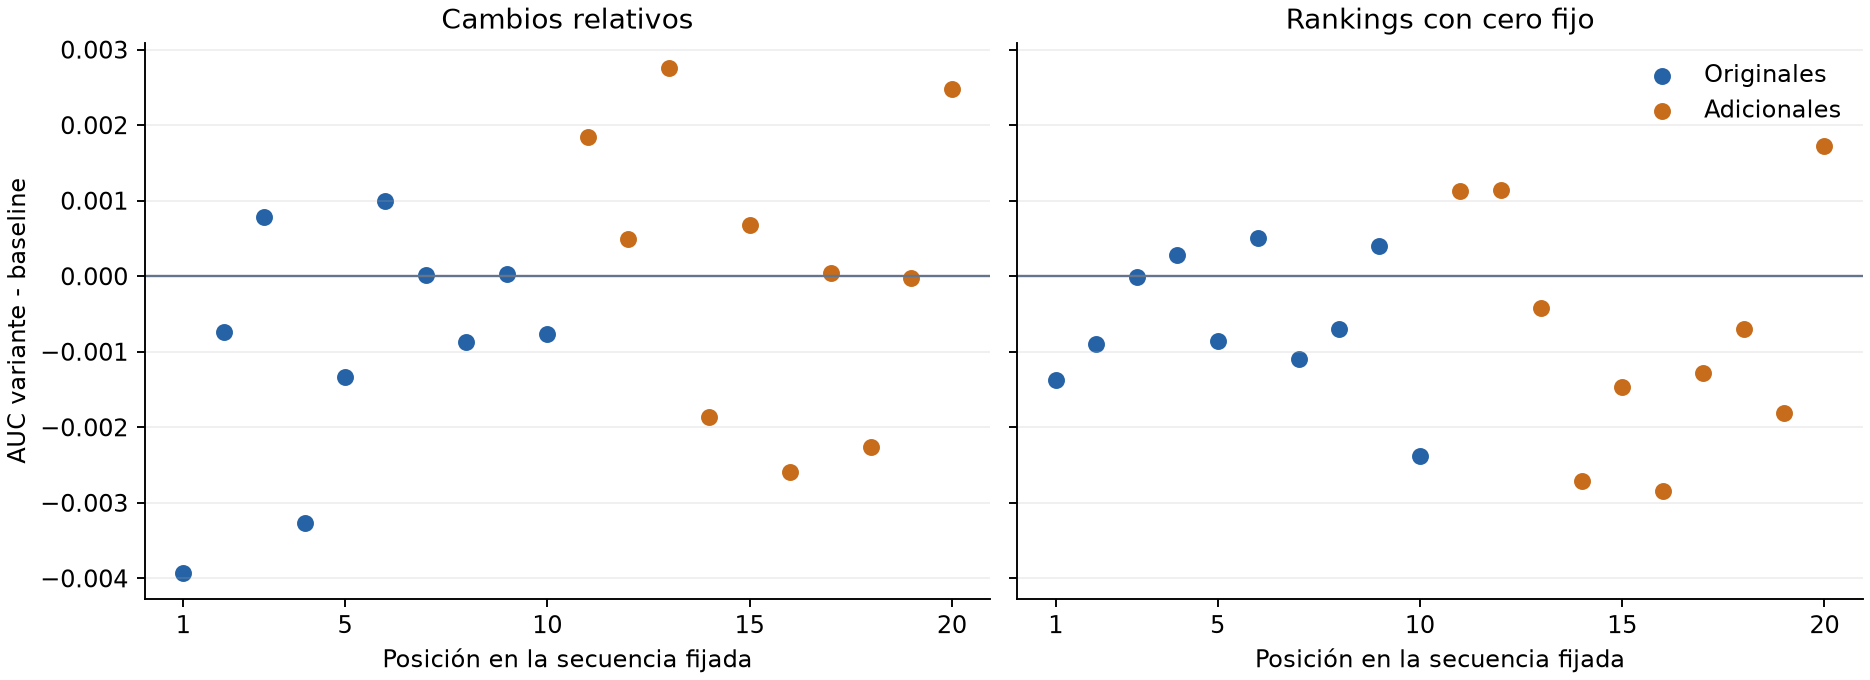

In [5]:
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
for ax, family in zip(axes, EXPANDED):
    data = differences20[differences20.familia == LABELS[family]]
    for name, color in [('Originales', '#2563a6'), ('Adicionales', '#c76c1a')]:
        part = data[data.grupo == name]
        ax.scatter(part['posición'], part['delta AUC'], label=name, color=color, s=38)
    ax.axhline(0, color='#64748b', lw=1)
    ax.set(title=LABELS[family], xlabel='Posición en la secuencia fijada')
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.grid(axis='y', alpha=.2)
axes[0].set_ylabel('AUC variante - baseline')
axes[1].legend(frameon=False)
fig.savefig(OUTPUT / 'auc_20semillas.png', dpi=170)
display(Image(filename=str(OUTPUT / 'auc_20semillas.png')))
plt.close(fig)

### ¿La ganancia se sostiene en las diez adicionales?

Media de diferencias de banda, en millones del ejercicio. No se muestran intervalos temporales ni se elige el corte más favorable.

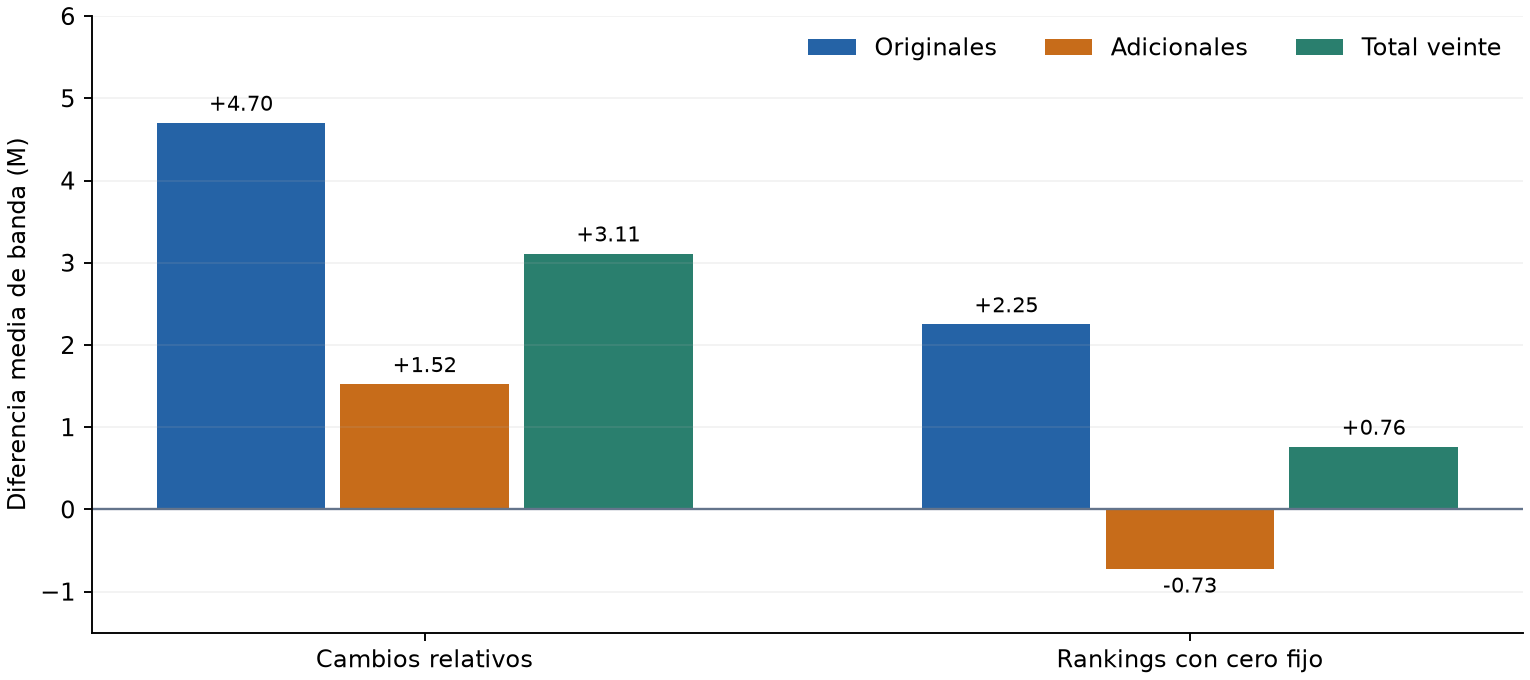

In [6]:
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
x = np.arange(len(EXPANDED))
for offset, name, color in [(-.24, 'Originales', '#2563a6'), (0, 'Adicionales', '#c76c1a'), (.24, 'Total veinte', '#2a7f6e')]:
    values = [float(groups20[(groups20.familia == LABELS[f]) & (groups20.grupo == name)]['delta banda media M'].iloc[0]) for f in EXPANDED]
    bars = ax.bar(x + offset, values, width=.22, label=name, color=color)
    ax.bar_label(bars, fmt='%+.2f', padding=3, fontsize=9)
ax.axhline(0, color='#64748b', lw=1)
ax.set_xticks(x, [LABELS[f] for f in EXPANDED])
ax.set_ylabel('Diferencia media de banda (M)')
ax.set_ylim(-1.5, 6)
ax.legend(frameon=False, ncol=3)
ax.grid(axis='y', alpha=.15)
fig.savefig(OUTPUT / 'ganancia_grupos_20semillas.png', dpi=170)
display(Image(filename=str(OUTPUT / 'ganancia_grupos_20semillas.png')))
plt.close(fig)

### Cobertura de las features

Fracción de faltantes en agosto calculada durante las corridas. Es un diagnóstico de disponibilidad; no demuestra mejoras en segmentos ni equivale a un experimento de disponibilidad ejecutado.

In [7]:
coverage_rows = []
for family in FAMILIES:
    coverage = pd.read_csv(TEN / family / 'extra_coverage.csv')
    coverage_rows.append({'familia': LABELS[family], 'features extra': len(coverage),
                          'faltantes promedio': coverage.missing_fraction.mean(),
                          'faltantes máximo': coverage.missing_fraction.max()})
display(pd.DataFrame(coverage_rows).round(4))

,familia,features extra,faltantes promedio,faltantes máximo
0,Historia reciente,387,0.1039,1.0000
1,Cambios relativos,258,0.0913,1.0000
2,Persistencia,516,0.1039,1.0000
3,Rankings con cero fijo,365,0.1066,0.6316


### Cierre de esta tanda y lectura para tutoría

Cambios relativos muestra una mejora media de banda de +3,1109 M y 15 de 20 semillas favorables. Rankings muestra +0,7599 M y 11 de 20 favorables. Ambas estrategias reducen la AUC media frente a ACO. Dentro de agosto, la señal económica resulta más consistente para cambios relativos; no se declara una ganadora confirmada.

La evaluación económica es secundaria y la cantidad de veinte semillas se fijó después de una exploración inicial con diez. Sigue siendo una ampliación exploratoria, no una prueba independiente. Agosto también intervino en el ajuste del baseline: las semillas describen variación del algoritmo y no añaden meses de validación.

No quedan entrenamientos pendientes de esta tanda. No se sumarán semillas para fortalecer el resultado; una evaluación temporal adicional requiere un protocolo nuevo. Los detalles de auditoría y el desglose por bloques de semillas se conservan en docs/auditoria_bins_20261107.md y en el notebook técnico.

El registro de historia reciente y persistencia, incluidos sus resultados negativos o pequeños, permanece en el notebook y los agregados de diez semillas. Esta sección presenta las dos estrategias que completaron veinte pares.




## Trazabilidad y estado de cierre

- Fuentes grupales actuales: `6cf189c`; `3b44f21` es solo un antecedente histórico, no la fuente vigente de 09-14.
- Auditoría: `docs/auditoria_bins_20261107.md`. Los NPY y claves de clientes permanecen en VM/bucket; este notebook solo utiliza agregados.
- No quedan entrenamientos pendientes ni reanudación automática. Los respaldos de las dos ampliaciones se verificaron y la VM quedó apagada.
- Historia reciente no habilitó búsqueda de pesos por su resultado de AUC. Autocorrelación y disponibilidad son propuestas no ejecutadas, sin cola activa.
- Siguen pendientes las respuestas del tutor y tablas fuente de diagnósticos macro/segmentos. La bibliografía metodológica se verificó con fuentes primarias. No se atribuyen al tutor respuestas inventadas.
- Septiembre/octubre ya fueron consultados por el grupo; noviembre/diciembre siguen reservados para dashboard. Un nuevo experimento requiere protocolo explícito.

Las versiones impresas debajo son las de **entrenamiento**, conservadas en config.json. El entorno actual del notebook solo calcula tablas y gráficos y no tiene que reproducir esas versiones para volver a entrenar.


In [8]:
version_rows = []
for family in EXPANDED:
    version_rows.append({'familia': LABELS[family], **configs[20, family]['versions']})
display(pd.DataFrame(version_rows))
print('SHA256 de los agregados verificados:', len(sources['sha256']))
print('Salidas de documentación:', OUTPUT)

,familia,pandas,numpy,duckdb,lightgbm,scikit-learn
0,Cambios relativos,2.3.3,2.4.3,1.5.5,4.7.0,1.8.0
1,Rankings con cero fijo,2.3.3,2.4.3,1.5.5,4.7.0,1.8.0


SHA256 de los agregados verificados: 10
Salidas de documentación: C:\Users\tomas\OneDrive\Documents\Maestria\DMEyF\dmeyf2026\Tp_experimentos\output\tutoria


## Bibliografía metodológica verificada

Fuentes primarias consultadas el 7 de noviembre de 2026. Respaldan conceptos y
herramientas; las métricas del trabajo provienen de los agregados y manifiestos
del repositorio. Esta revisión no recalcula los contrastes de los compañeros.

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q. y Liu, T.-Y.
  (2017). [LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html).
  Advances in Neural Information Processing Systems 30. Artículo del software usado.
- Proyecto LightGBM. [Parameters](https://lightgbm.readthedocs.io/en/stable/Parameters.html).
  Documenta seed, data_random_seed y muestreo para construir bins. La auditoría
  concreta del trabajo se verificó además mediante predicciones idénticas.
- Proyecto scikit-learn. [roc_auc_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).
  Define el cálculo de ROC-AUC desde scores. No sustituye la función económica
  particular de la consigna, que se documenta por separado.
- Proyecto SciPy. [scipy.stats.wilcoxon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html).
  Describe el contraste de rangos con signo para pares y las precauciones con
  ceros, empates y método exacto. Los p del informe se atribuyen a sus tablas fuente.
- Proyecto statsmodels. [multipletests](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html).
  Documenta Holm como corrección escalonada basada en Bonferroni para múltiples
  contrastes. La regla de seis contrastes es una decisión del grupo.
- Proyecto scikit-learn. [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).
  Referencia conceptual sobre particiones con orden temporal. No se afirma haber
  usado esta clase: el trabajo usa los meses y particiones descritos en su protocolo.

Las páginas de documentación pueden mostrar versiones posteriores al entorno de
entrenamiento. Las versiones efectivamente usadas siguen registradas en cada
config.json; consultar estas referencias no cambia la configuración de las corridas.
